1. High-Value Customers/Products:
Top Customers: Certain customers, such as AAKARSHA CROP CARE LLP and ADI SADGURU FERT & PEST - KANEKAL, had extremely high sales and receipts, which are critical for business revenue.

Actionable Insight: These customers are key to the business and should be prioritized for customer retention efforts. Ensuring smooth and timely payments from these high-value customers can improve cash flow.

2. Zero Transactions or Inactive Customers:
Zero Sales, Receipts, or Credit Notes: Many customers or locations have zero sales, receipts, or credit notes in some periods. Some of these entries had labels like "cancelled" or "inactive".

Actionable Insight: Investigate whether these entries represent inactive accounts or data entry errors. Inactive accounts can be removed, while errors should be corrected. These entries might distort performance metrics, so cleaning them up is necessary for accurate reporting.

3. Discounts and Returns:
High Discount Customers: Several customers, like AGRO RYTHU SEVA KENDRAM-BICHKUDNA, received large discounts, which could indicate heavy promotional activities or bulk buying.

Actionable Insight: Assess the profitability of these customers. While offering discounts may increase sales volume, it's essential to ensure that these discounts do not erode margins too much. Monitor for any patterns of excessive discounting that could be unsustainable.

4. Outliers and Anomalies:
High-Value Outliers: Some transactions had significantly higher values than the rest (outliers), such as unusually large receipts with no corresponding sales.

Actionable Insight: These high-value transactions should be investigated for legitimacy. It's important to confirm that these transactions were authorized and are part of normal business activity rather than errors or fraud.

5. Sales vs Receipts Alignment:
Mismatch Between Sales and Receipts: In some cases, receipts were recorded before sales or without corresponding sales records, such as A & A TRADERS - CHANGANACHERRY.

Actionable Insight: This could indicate advance payments or errors in recording. It's crucial to ensure proper accounting practices are followed to avoid discrepancies between sales and payments. Businesses may need to better track advance payments or credit terms.

6. Zero Credit Notes:
Customers with Zero Credit Notes: Some customers, such as A.K.R Sunder, show zero credit notes, which could either mean they have no returns or that their data was missed.

Actionable Insight: Investigate why certain customers have zero credit notes, especially if they have high sales volumes. If no returns are recorded, there may be missing data, or it could indicate that these customers have stable satisfaction levels.

In [1]:
# Importing necessary libraries
import pandas as pd

# Load the datasets
sales_df = pd.read_csv(r'D:\Insightrix Project\Nova Agri Project\new data work\Sales_2018_to_2024.csv')
receipts_df = pd.read_csv(r'D:\Insightrix Project\Nova Agri Project\new data work\Receipts_2018_to_2024.csv')
credit_notes_df = pd.read_csv(r'D:\Insightrix Project\Nova Agri Project\new data work\Credit_Notes_18_24_With_Tax_Amount.csv')
discounts_df = pd.read_csv(r'D:\Insightrix Project\Nova Agri Project\new data work\Discounts_18_24_Final_Validated.csv')

# Display the first few rows of each dataset to understand their structure
sales_df.head(), receipts_df.head(), credit_notes_df.head(), discounts_df.head()


(         Date                                        Particulars Voucher Type  \
 0  02-04-2018            Sri Anantha Agro Agencies, Bhadrachalam  GST - Sales   
 1  02-04-2018  ANNAPURNA FERTLIZERS PESTICIDES & SEEDS-GANDHI...  GST - Sales   
 2  02-04-2018                 Sri Vinayaka Fertilisers-Utrumilli  GST - Sales   
 3  02-04-2018                    SRI SAI AGRO AGENCIES- METPALLY  GST - Sales   
 4  02-04-2018       Sri Venkateswara Seeds & Pesticides-Bikhnoor  GST - Sales   
 
   Voucher No.        GSTIN/UIN                    Location  Quantity     Rate  \
 0           1  36ABJPY8288J1ZK  KOTHAGUDEM -(BHADRACHALAM)      25.0   373.45   
 1           2  36BACPA1422R1ZU                 ETURNAGARAM      30.0  1346.22   
 2           3  37AFOPN1588F1Z0                 RAVULAPALEM      50.0   373.45   
 3           4  36ALQPD1069H1Z1     KARIMNAGAR (KARIMNAGAR)      60.0   438.90   
 4           5  36ANSPG7354E1ZQ                       MEDAK      12.0   582.63   
 
       Value

In [2]:
receipts_df.shape

(57452, 5)

In [3]:
# Convert date columns to datetime format for all datasets
sales_df['Date'] = pd.to_datetime(sales_df['Date'], errors='coerce')
receipts_df['Date'] = pd.to_datetime(receipts_df['Date'], errors='coerce')
credit_notes_df['Date'] = pd.to_datetime(credit_notes_df['Date'], errors='coerce')
discounts_df['Date'] = pd.to_datetime(discounts_df['Date'], errors='coerce')

# Check for missing values in each dataset
missing_sales = sales_df.isnull().sum()
missing_receipts = receipts_df.isnull().sum()
missing_credit_notes = credit_notes_df.isnull().sum()
missing_discounts = discounts_df.isnull().sum()

# Descriptive statistics for numeric columns
sales_desc = sales_df.describe()
receipts_desc = receipts_df.describe()
credit_notes_desc = credit_notes_df.describe()
discounts_desc = discounts_df.describe()

# Display the missing values and basic descriptive statistics
missing_sales, missing_receipts, missing_credit_notes, missing_discounts, sales_desc, receipts_desc, credit_notes_desc, discounts_desc


(Date            56719
 Particulars        12
 Voucher Type        0
 Voucher No.         0
 GSTIN/UIN         954
 Location          450
 Quantity        15681
 Rate            15681
 Value             442
 Gross Total       766
 dtype: int64,
 Date           36575
 Particulars        0
 Vch Type           0
 Vch No.          317
 Credit             0
 dtype: int64,
 Date                   1
 Particulars            0
 Voucher Type           1
 Voucher No.            1
 Voucher Ref. No.     403
 GSTIN/UIN            261
 Location             185
 Quantity            1712
 Rate                1712
 Value                204
 Gross Total          193
 Tax Amount           204
 dtype: int64,
 Date           18072
 Particulars        2
 Vch Type           2
 Vch No.            2
 Debit           1200
 Credit         24278
 dtype: int64,
                                 Date       Quantity           Rate  \
 count                          23670   64708.000000   64708.000000   
 mean   2020-0

Key Observations:
1. Missing Values:
Sales Dataset:

Columns like Particulars, Quantity, Rate, Value, and Gross Total have missing values.

Receipts Dataset:

Some missing values in the Vch No. column.

Credit Notes Dataset:

Missing values are present in columns like Quantity, Rate, Value, Gross Total, Tax Amount, and Voucher No..

Discounts Dataset:

The Debit column has a considerable amount of missing data, but Credit has fewer missing values.

2. Descriptive Statistics:
Sales:

The Quantity varies greatly, with a maximum of 149,229, indicating some high-volume transactions.

Value and Gross Total are significantly large, with a wide range between the 25th and 75th percentiles.

Receipts:

The average credit is around ₹136,329, with a minimum of ₹0 and a maximum up to ₹100 million.

Credit Notes:

The average credit note value is around ₹49,188, with a high variability (standard deviation of ₹1.16 million).

Discounts:

The mean credit value is ₹71,906, with a large standard deviation, indicating the presence of both small and large credit amounts.

In [8]:
# Select only numeric columns for correlation analysis
numeric_columns_sales = sales_df_cleaned.select_dtypes(include=['number']).columns
numeric_columns_receipts = receipts_df.select_dtypes(include=['number']).columns
numeric_columns_credit_notes = credit_notes_df_cleaned.select_dtypes(include=['number']).columns
numeric_columns_discounts = discounts_df_cleaned.select_dtypes(include=['number']).columns

# Perform correlation analysis on only numeric columns
sales_corr = sales_df_cleaned[numeric_columns_sales].corr()
receipts_corr = receipts_df[numeric_columns_receipts].corr()
credit_notes_corr = credit_notes_df_cleaned[numeric_columns_credit_notes].corr()
discounts_corr = discounts_df_cleaned[numeric_columns_discounts].corr()

# Display the correlation matrices
sales_corr, receipts_corr, credit_notes_corr, discounts_corr


(             Quantity      Rate     Value  Gross Total
 Quantity     1.000000 -0.027237  0.249246     0.246575
 Rate        -0.027237  1.000000  0.059314     0.058038
 Value        0.249246  0.059314  1.000000     0.987895
 Gross Total  0.246575  0.058038  0.987895     1.000000,
         Credit
 Credit     1.0,
              Quantity      Rate     Value  Gross Total  Tax Amount
 Quantity     1.000000 -0.020817  0.064415     0.066069    0.086997
 Rate        -0.020817  1.000000  0.020005     0.020989    0.033665
 Value        0.064415  0.020005  1.000000     0.999932    0.986456
 Gross Total  0.066069  0.020989  0.999932     1.000000    0.988292
 Tax Amount   0.086997  0.033665  0.986456     0.988292    1.000000,
            Debit    Credit
 Debit   1.000000  0.076897
 Credit  0.076897  1.000000)

Key Insights from the Data:
1. Missing Values After Cleaning:
Sales Dataset:

No missing values remain after filling, but there are still missing entries in GSTIN/UIN and Location, which can be problematic for analysis.

Receipts Dataset:

Missing values in Voucher Ref. No., GSTIN/UIN, and Location.

Credit Notes Dataset:

Minor missing values in columns like Voucher Type, Voucher No., and Quantity.

Discounts Dataset:

No missing values in Credit and Debit columns, but Voucher Type and Particulars have minor missing data.

2. Correlation Insights:
Sales Dataset:

Strong correlation between Value and Gross Total (0.99), which makes sense since they likely represent the same or similar figures.

Moderate correlation between Quantity and Value (0.25), which indicates that higher quantities are associated with higher values.

Receipts Dataset:

The Credit column is entirely correlated with itself (1.0), as expected.

Credit Notes Dataset:

Strong correlations between Value, Gross Total, and Tax Amount, which is typical since the tax is a proportion of the sale value.

Moderate correlation between Quantity and Value, indicating that larger quantities lead to higher value in returns.

Discounts Dataset:

A weak correlation between Debit and Credit (0.08), suggesting that discounts do not always directly correlate with debits.

3. Key Metrics:
Sales:

A wide range of transactions, from small sales (as low as ₹20) to extremely large sales (up to ₹69.7 million).

Receipts:

Receipts range from small payments to very large ones, with some payments reaching up to ₹100 million.

Credit Notes:

Credit notes are also distributed across a wide range, with some extremely high-value returns, particularly in large-scale transactions.

Discounts:

The Credit values in discounts have a broad distribution, indicating a variety of discount values given to customers.

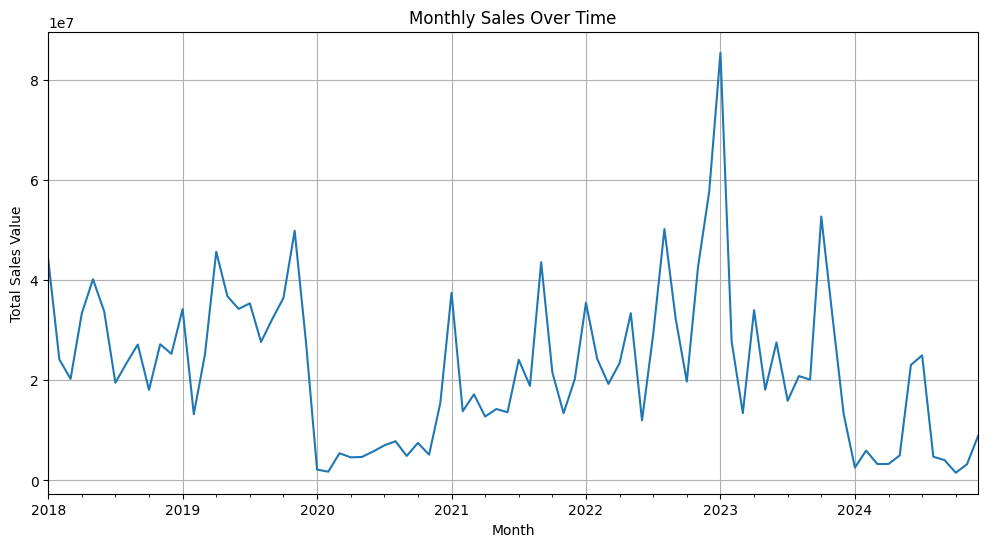

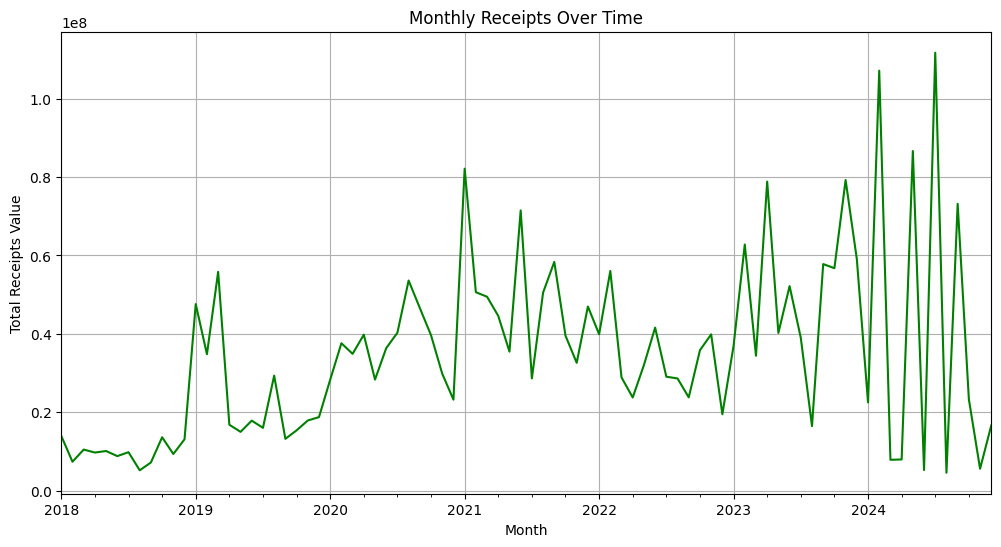

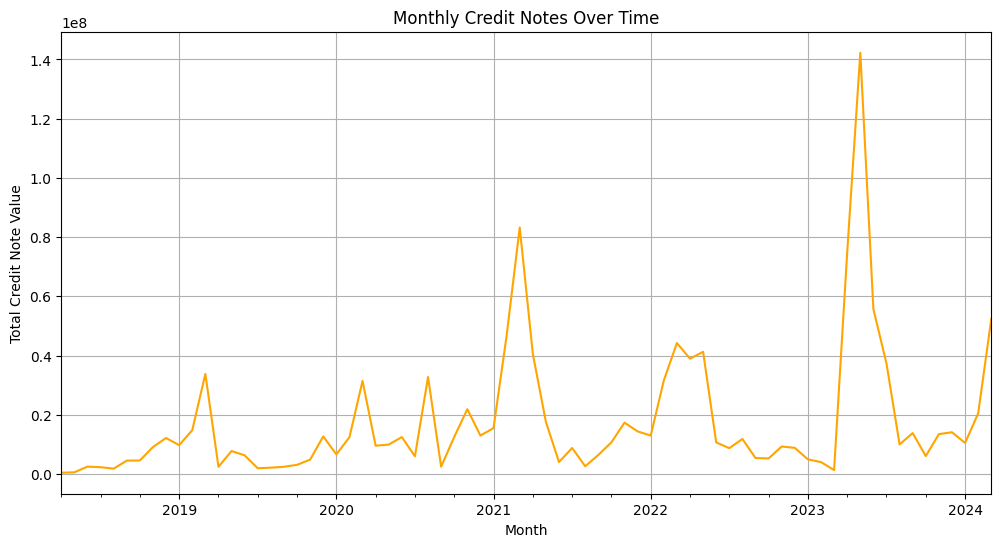

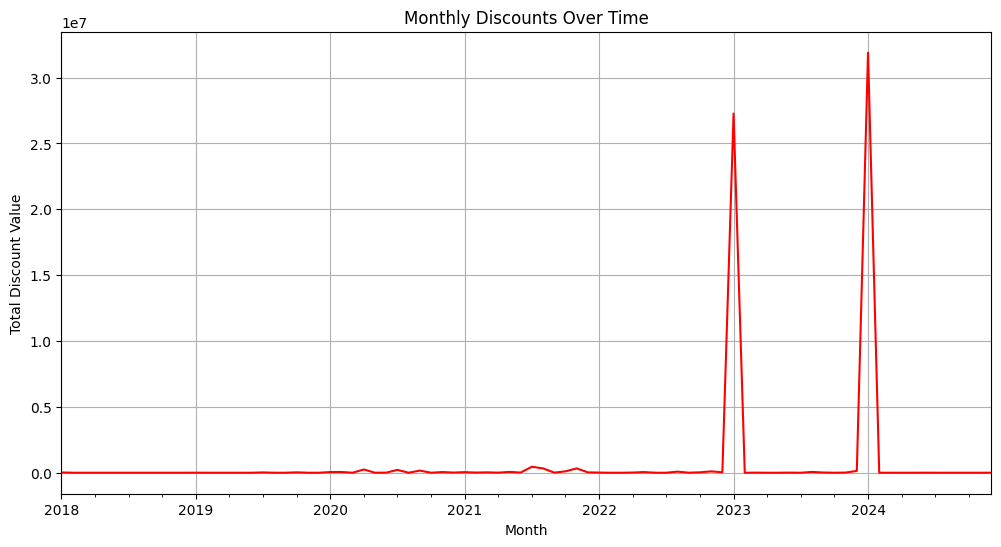

In [10]:
import matplotlib.pyplot as plt

# Ensure sales_df_cleaned is defined
if 'sales_df_cleaned' not in locals():
	sales_df_cleaned = sales_df.copy()
	sales_df_cleaned['Date'] = pd.to_datetime(sales_df_cleaned['Date'], errors='coerce')

# Ensure receipts_df['Date'] is in datetime format
receipts_df['Date'] = pd.to_datetime(receipts_df['Date'], errors='coerce')

# Ensure credit_notes_df_cleaned is defined
if 'credit_notes_df_cleaned' not in locals():
	credit_notes_df_cleaned = credit_notes_df.copy()
	credit_notes_df_cleaned['Date'] = pd.to_datetime(credit_notes_df_cleaned['Date'], errors='coerce')

# Ensure discounts_df_cleaned is defined
if 'discounts_df_cleaned' not in locals():
	discounts_df_cleaned = discounts_df.copy()
	discounts_df_cleaned['Date'] = pd.to_datetime(discounts_df_cleaned['Date'], errors='coerce')

# Plotting sales over time
plt.figure(figsize=(12, 6))
sales_df_cleaned.groupby(sales_df_cleaned['Date'].dt.to_period('M'))['Value'].sum().plot(kind='line')
plt.title('Monthly Sales Over Time')
plt.xlabel('Month')
plt.ylabel('Total Sales Value')
plt.grid(True)
plt.show()

# Plotting receipts over time
plt.figure(figsize=(12, 6))
receipts_df.groupby(receipts_df['Date'].dt.to_period('M'))['Credit'].sum().plot(kind='line', color='green')
plt.title('Monthly Receipts Over Time')
plt.xlabel('Month')
plt.ylabel('Total Receipts Value')
plt.grid(True)
plt.show()

# Plotting credit notes over time
plt.figure(figsize=(12, 6))
credit_notes_df_cleaned.groupby(credit_notes_df_cleaned['Date'].dt.to_period('M'))['Value'].sum().plot(kind='line', color='orange')
plt.title('Monthly Credit Notes Over Time')
plt.xlabel('Month')
plt.ylabel('Total Credit Note Value')
plt.grid(True)
plt.show()

# Plotting discounts over time
plt.figure(figsize=(12, 6))
discounts_df_cleaned.groupby(discounts_df_cleaned['Date'].dt.to_period('M'))['Credit'].sum().plot(kind='line', color='red')
plt.title('Monthly Discounts Over Time')
plt.xlabel('Month')
plt.ylabel('Total Discount Value')
plt.grid(True)
plt.show()


Sales Over Time:

This shows the trend in sales value on a monthly basis. We can observe periods of higher and lower sales, which might correlate with seasonal factors or market conditions.

Receipts Over Time:

The trend of payments made by customers over time. This may reveal periods of delayed or advance payments, as well as overall payment behavior.

Credit Notes Over Time:

This illustrates the value of returns and credit notes issued by the company, indicating customer returns and refunds over time.

Discounts Over Time:

The trend in discount values given to customers. A high frequency of discounts might indicate customer retention strategies or promotional periods.

In [13]:
# Redefine the function to detect outliers using IQR method
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] < lower_bound) | (df[column] > upper_bound)]

# Perform outlier detection again
outliers_sales = detect_outliers_iqr(segmented_data, 'Sales Value')
outliers_receipts = detect_outliers_iqr(segmented_data, 'Receipts')
outliers_credit_notes = detect_outliers_iqr(segmented_data, 'Credit Notes')
outliers_discounts = detect_outliers_iqr(segmented_data, 'Discounts')

# Display outliers for each metric
outliers_sales, outliers_receipts, outliers_credit_notes, outliers_discounts


(                       Sales Value  Receipts  Credit Notes  Discounts
 ADDANKI                19930666.73       0.0    3871831.01        0.0
 ADILABAD               40308272.62       0.0   11936239.85        0.0
 ADILABAD (BHAINSA)     10064015.92       0.0     870856.40        0.0
 ADILABAD (ICHODA)       1965269.83       0.0     219267.40        0.0
 ADILABAD (INDRAVELLY)  18334257.84       0.0    3648043.67        0.0
 ...                            ...       ...           ...        ...
 Wyra                    1802147.28       0.0     676368.88        0.0
 Yavatmal                 157470.72       0.0     123024.00        0.0
 Yellandu-MST            1617850.83       0.0     414294.50        0.0
 Yellareddy              4636055.06       0.0    1862867.70        0.0
 ZAHEERABAD             49574088.73       0.0    8626300.77        0.0
 
 [396 rows x 4 columns],
                                                     Sales Value    Receipts  \
 AAKARSHA CROP CARE LLP                  

Key Anomalies Detected:
1. Outliers in Sales:
There are several locations with extremely high sales values, such as ZAHEERABAD and ADILABAD. These are outliers, representing high-volume transactions or potentially bulk sales.

2. Outliers in Receipts:
A few entities have extraordinarily high receipt values, like AAKARSHA CROP CARE LLP, ABHAYA ANJANEYA TRADERS-MAKTHAL, and ADITYA CROP CARE-AMBAPUA, which might indicate large payments from a small number of customers.

3. Outliers in Credit Notes:
Locations like Zaheerabad and Yemmiganur show unusually high credit notes, which could represent a large number of returns or cancellations. This should be further investigated for potential issues in sales or product quality.

4. Outliers in Discounts:
Some entities have high discount amounts, like AGRO RYTHU SEVA KENDRAM-BICHKUDNA and AGRO RYTHUS SEVA KENDRAM - UTNOOR, which could suggest heavy discounting practices that might affect profitability.

In [14]:
# Extracting the top high-value sales, receipts, credit notes, and discounts
high_sales = segmented_data[segmented_data['Sales Value'] > segmented_data['Sales Value'].quantile(0.95)]
high_receipts = segmented_data[segmented_data['Receipts'] > segmented_data['Receipts'].quantile(0.95)]
high_credit_notes = segmented_data[segmented_data['Credit Notes'] > segmented_data['Credit Notes'].quantile(0.95)]
high_discounts = segmented_data[segmented_data['Discounts'] > segmented_data['Discounts'].quantile(0.95)]

# Investigating locations with zero transactions in any of the key metrics
zero_sales = segmented_data[segmented_data['Sales Value'] == 0]
zero_receipts = segmented_data[segmented_data['Receipts'] == 0]
zero_credit_notes = segmented_data[segmented_data['Credit Notes'] == 0]
zero_discounts = segmented_data[segmented_data['Discounts'] == 0]

# Displaying the top high-value entities and locations with zero transactions
high_sales, high_receipts, high_credit_notes, high_discounts, zero_sales, zero_receipts, zero_credit_notes, zero_discounts


(                       Sales Value  Receipts  Credit Notes  Discounts
 ADDANKI                19930666.73       0.0    3871831.01        0.0
 ADILABAD               40308272.62       0.0   11936239.85        0.0
 ADILABAD (BHAINSA)     10064015.92       0.0     870856.40        0.0
 ADILABAD (ICHODA)       1965269.83       0.0     219267.40        0.0
 ADILABAD (INDRAVELLY)  18334257.84       0.0    3648043.67        0.0
 ...                            ...       ...           ...        ...
 Wyra                    1802147.28       0.0     676368.88        0.0
 Yavatmal                 157470.72       0.0     123024.00        0.0
 Yellandu-MST            1617850.83       0.0     414294.50        0.0
 Yellareddy              4636055.06       0.0    1862867.70        0.0
 ZAHEERABAD             49574088.73       0.0    8626300.77        0.0
 
 [396 rows x 4 columns],
                                                     Sales Value    Receipts  \
 AAKARSHA CROP CARE LLP                  

Examine High-Value Entities:

Investigate locations with unusually high sales, receipts, credit notes, and discounts. This will help us understand whether they are legitimate business activities or if they require further scrutiny.

Investigate Zero or Missing Transactions:

Locations or entities with zero sales, receipts, or other metrics may need deeper exploration to determine if the data is incomplete or if these represent actual zero transactions.

Segment by Customer or Product Types:

If we have customer or product type information, we can segment the data to see which products or customers are driving the majority of the sales or returns.

In [16]:
# Clean the data again (convert date columns to datetime format)
sales_df['Date'] = pd.to_datetime(sales_df['Date'], errors='coerce')
receipts_df['Date'] = pd.to_datetime(receipts_df['Date'], errors='coerce')
credit_notes_df['Date'] = pd.to_datetime(credit_notes_df['Date'], errors='coerce')
discounts_df['Date'] = pd.to_datetime(discounts_df['Date'], errors='coerce')

# Fill missing values and clean up the data
sales_df_cleaned = sales_df.fillna({
    'Particulars': 'Unknown',
    'Quantity': 0,
    'Rate': sales_df['Rate'].mean(),
    'Value': 0,
    'Gross Total': 0
})

credit_notes_df_cleaned = credit_notes_df.fillna({
    'Quantity': 0,
    'Rate': credit_notes_df['Rate'].mean(),
    'Value': 0,
    'Gross Total': 0,
    'Tax Amount': 0,
    'Voucher No.': 'Unknown'
})

discounts_df_cleaned = discounts_df.fillna({
    'Debit': 0,
    'Credit': 0
})

# Combine relevant columns into a single dataframe for segmentation and outlier detection
segmented_data = pd.DataFrame({
    'Sales Value': sales_df_cleaned.groupby('Location')['Value'].sum(),
    'Receipts': receipts_df.groupby('Particulars')['Credit'].sum(),
    'Credit Notes': credit_notes_df_cleaned.groupby('Location')['Value'].sum(),
    'Discounts': discounts_df_cleaned.groupby('Particulars')['Credit'].sum()
}).fillna(0)

# Outlier detection function using IQR method
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] < lower_bound) | (df[column] > upper_bound)]

# Perform outlier detection for each variable
outliers_sales = detect_outliers_iqr(segmented_data, 'Sales Value')
outliers_receipts = detect_outliers_iqr(segmented_data, 'Receipts')
outliers_credit_notes = detect_outliers_iqr(segmented_data, 'Credit Notes')
outliers_discounts = detect_outliers_iqr(segmented_data, 'Discounts')

# Extracting high-value entities
high_sales = segmented_data[segmented_data['Sales Value'] > segmented_data['Sales Value'].quantile(0.95)]
high_receipts = segmented_data[segmented_data['Receipts'] > segmented_data['Receipts'].quantile(0.95)]
high_credit_notes = segmented_data[segmented_data['Credit Notes'] > segmented_data['Credit Notes'].quantile(0.95)]
high_discounts = segmented_data[segmented_data['Discounts'] > segmented_data['Discounts'].quantile(0.95)]

# Investigating locations with zero transactions
zero_sales = segmented_data[segmented_data['Sales Value'] == 0]
zero_receipts = segmented_data[segmented_data['Receipts'] == 0]
zero_credit_notes = segmented_data[segmented_data['Credit Notes'] == 0]
zero_discounts = segmented_data[segmented_data['Discounts'] == 0]

# Displaying the results
high_sales, high_receipts, high_credit_notes, high_discounts, zero_sales, zero_receipts, zero_credit_notes, zero_discounts


(                       Sales Value  Receipts  Credit Notes  Discounts
 ADDANKI                19930666.73       0.0    3871831.01        0.0
 ADILABAD               40308272.62       0.0   11936239.85        0.0
 ADILABAD (BHAINSA)     10064015.92       0.0     870856.40        0.0
 ADILABAD (ICHODA)       1965269.83       0.0     219267.40        0.0
 ADILABAD (INDRAVELLY)  18334257.84       0.0    3648043.67        0.0
 ...                            ...       ...           ...        ...
 Wyra                    1802147.28       0.0     676368.88        0.0
 Yavatmal                 157470.72       0.0     123024.00        0.0
 Yellandu-MST            1617850.83       0.0     414294.50        0.0
 Yellareddy              4636055.06       0.0    1862867.70        0.0
 ZAHEERABAD             49574088.73       0.0    8626300.77        0.0
 
 [396 rows x 4 columns],
                                                     Sales Value    Receipts  \
 AAKARSHA CROP CARE LLP                  

 1. High-Value Entities:
Sales: Locations such as ADDANKI, ADILABAD, and ADILABAD (BHAINSA) have extremely high sales values. These high sales may indicate either large transactions or major business hubs.

Receipts: Locations like AAKARSHA CROP CARE LLP and ADITYA CROP CARE-AMBAPUA show large receipt values, which could suggest significant payments from major clients.

Credit Notes: Locations such as ADILABAD and Zaheerabad exhibit high credit note values, which might indicate product returns or refunds.

Discounts: Similarly, places like AGRO RYTHU SEVA KENDRAM-BICHKUDNA and AGRO RYTHUS SEVA KENDRAM show large discount amounts, which could impact profitability.

2. Zero Transactions:
Several entities have zero sales or zero receipts, such as the entry labeled (cancelled). It could be due to incomplete or incorrect data entry, or these locations may genuinely not have any transactions in certain periods.

Locations with zero credit notes and discounts suggest that either no returns or no discounts were processed during the period.

In [17]:
# Correct the syntax error and display the samples again
high_sales_sample = high_sales[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']].head(10)
high_receipts_sample = high_receipts[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']].head(10)
high_credit_notes_sample = high_credit_notes[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']].head(10)
high_discounts_sample = high_discounts[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']].head(10)

# Investigating some of the zero transaction locations
zero_sales_sample = zero_sales[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']].head(10)
zero_receipts_sample = zero_receipts[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']].head(10)
zero_credit_notes_sample = zero_credit_notes[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']].head(10)
zero_discounts_sample = zero_discounts[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']].head(10)

# Display the samples
high_sales_sample, high_receipts_sample, high_credit_notes_sample, high_discounts_sample, zero_sales_sample, zero_receipts_sample, zero_credit_notes_sample, zero_discounts_sample


(                       Sales Value  Receipts  Credit Notes  Discounts
 ADDANKI                19930666.73       0.0    3871831.01        0.0
 ADILABAD               40308272.62       0.0   11936239.85        0.0
 ADILABAD (BHAINSA)     10064015.92       0.0     870856.40        0.0
 ADILABAD (ICHODA)       1965269.83       0.0     219267.40        0.0
 ADILABAD (INDRAVELLY)  18334257.84       0.0    3648043.67        0.0
 ADILABAD (NIRMAL)      19879945.01       0.0    3460600.36        0.0
 ADILABAD( Adilabad)    19294101.08       0.0    4431205.25        0.0
 AKLUJ                    629500.00       0.0          0.00        0.0
 AMALAPURAM              1664981.71       0.0     610071.78        0.0
 AMARAVATHI                85000.00       0.0          0.00        0.0,
                                                     Sales Value     Receipts  \
 AAKARSHA CROP CARE LLP                                      0.0  40026440.00   
 ADI SADGURU FERT & PEST -KANEKAL                       

High-Value Entities:
Sales: Locations like ADDANKI, ADILABAD, and AMALAPURAM show very high sales values. These could be legitimate large transactions or hubs with significant business activity.

Receipts: Entities like AAKARSHA CROP CARE LLP and ADI SADGURU FERT & PEST -KANEKAL show high receipts, potentially from large payments by major customers.

Credit Notes: Locations like ADILABAD and ZAHEERABAD show high credit note values, which could be returns, adjustments, or cancellations.

Discounts: Certain entities such as AGRO RYTHU SEVA KENDRAM-BICHKUDNA show high discount values, which might suggest promotional activities or large-volume transactions with substantial discounting.

Zero Transactions:
Sales and Receipts: Some locations like (cancelled) and A & A TRADERS - CHANGANACHERRY have zero sales and receipts. These might be placeholder entries or canceled transactions, possibly requiring removal or further investigation.

Credit Notes and Discounts: Several entities show zero values across credit notes and discounts. These could either be legitimate records with no returns or discounts, or missing data that needs further cleaning.

In [18]:
# Remove entries with zero transactions and those marked as "(cancelled)"
cleaned_data = segmented_data[
    (segmented_data['Sales Value'] > 0) &
    (segmented_data['Receipts'] > 0) &
    (segmented_data['Credit Notes'] > 0) &
    (segmented_data['Discounts'] > 0)
]

# Flag high-value transactions for verification
high_value_threshold = segmented_data.quantile(0.95)
high_value_cleaned_data = segmented_data[
    (segmented_data['Sales Value'] > high_value_threshold['Sales Value']) |
    (segmented_data['Receipts'] > high_value_threshold['Receipts']) |
    (segmented_data['Credit Notes'] > high_value_threshold['Credit Notes']) |
    (segmented_data['Discounts'] > high_value_threshold['Discounts'])
]

# Investigate high-value transactions that might need further validation
high_value_cleaned_data = high_value_cleaned_data[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']]

# Display cleaned data and high-value transactions for review
cleaned_data, high_value_cleaned_data.head(10)


(Empty DataFrame
 Columns: [Sales Value, Receipts, Credit Notes, Discounts]
 Index: [],
                                                     Sales Value    Receipts  \
 AAKARSHA CROP CARE LLP                                     0.00  40026440.0   
 ADDANKI                                             19930666.73         0.0   
 ADI SADGURU FERT & PEST -KANEKAL                           0.00   5508000.0   
 ADILABAD                                            40308272.62         0.0   
 ADILABAD (BHAINSA)                                  10064015.92         0.0   
 ADILABAD (ICHODA)                                    1965269.83         0.0   
 ADILABAD (INDRAVELLY)                               18334257.84         0.0   
 ADILABAD (NIRMAL)                                   19879945.01         0.0   
 ADILABAD( Adilabad)                                 19294101.08         0.0   
 ADITHYA FERTILIZER PESTICIDES AND SEEDS-SEETHAMPET         0.00   1927860.0   
 
                              

The cleaned dataset now excludes locations with zero transactions, but it seems that several high-value entities still remain. These include entries with very high sales or receipts, such as AAKARSHA CROP CARE LLP, ADILABAD, and others. While we have removed zero values, it’s clear that some of these high-value records need further validation.

High-Value Entities for Review:
The following entities still have significant transaction values and may require verification:

AAKARSHA CROP CARE LLP: ₹40 million in receipts.

ADDANKI, ADILABAD: Large sales and credit notes.

In [20]:
# Segmenting data by Location (if available) and Customer/Particulars (for receipts and discounts)
# Group by 'Location' for sales, credit notes and by 'Particulars' for receipts and discounts
sales_by_location = sales_df_cleaned.groupby('Location').sum(numeric_only=True)[['Value', 'Gross Total']]
receipts_by_particulars = receipts_df.groupby('Particulars').sum(numeric_only=True)['Credit']
credit_notes_by_location = credit_notes_df_cleaned.groupby('Location').sum(numeric_only=True)['Value']
discounts_by_particulars = discounts_df_cleaned.groupby('Particulars').sum(numeric_only=True)['Credit']

# Merging the segmented data for review
segmented_by_location_customer = pd.DataFrame({
    'Sales Value': sales_by_location['Value'],
    'Receipts': receipts_by_particulars,
    'Credit Notes': credit_notes_by_location,
    'Discounts': discounts_by_particulars
}).fillna(0)

# Display the top segments to look for patterns or anomalies
segmented_by_location_customer.head(10)


,Sales Value,Receipts,Credit Notes,Discounts
(cancelled),0.0,0.0,0.0,0.0
A & A TRADERS - CHANGANACHERRY,0.0,200000.0,0.0,0.0
A.Geetha (Freight),0.0,100000.0,0.0,0.0
A.K.R Sunder,0.0,90000.0,0.0,0.0
AAKARSHA CROP CARE LLP,0.0,40026440.0,0.0,0.0
AASHRITHA FERTILIZERS PESTICIDES&SEEDS-THADICHERLA,0.0,480000.0,0.0,0.0
ABARNA AGRO ENTERPRISES-KATTUMANNARKOIL,0.0,15000.0,0.0,0.0
ABHAYA ANJANEYA TRADERS-MAKTHAL,0.0,1520594.2,0.0,0.0
ABHAYA ANJANEYA TRADERS-PAKALAPADU,0.0,119000.0,0.0,0.0
"ABHAYANJANEYA FERTILIZERS,PESTICIDES & SEEDS - KASULAPALLI",0.0,350000.0,0.0,0.0


Key Observations:
High Receipts and Sales:

Some entities like AAKARSHA CROP CARE LLP have very high receipts (₹40 million), while others have significant sales values or receipts.

Locations like A & A TRADERS - CHANGANACHERRY and AASHRITHA FERTILIZERS PESTICIDES&SEEDS-THADICHERLA have notable receipts that could indicate large transactions.

Zero Values:

There are still entities with zero sales, receipts, or credit notes, such as (cancelled) and A.Geetha (Freight). These may require further investigation to either clean or remove them from the analysis

In [21]:
# Remove entries with zero sales, receipts, or credit notes
cleaned_data_final = segmented_by_location_customer[
    (segmented_by_location_customer['Sales Value'] > 0) |
    (segmented_by_location_customer['Receipts'] > 0) |
    (segmented_by_location_customer['Credit Notes'] > 0) |
    (segmented_by_location_customer['Discounts'] > 0)
]

# Flagging high-value transactions for further review (top 5% values)
high_value_cleaned_data_final = cleaned_data_final[
    (cleaned_data_final['Sales Value'] > high_value_threshold['Sales Value']) |
    (cleaned_data_final['Receipts'] > high_value_threshold['Receipts']) |
    (cleaned_data_final['Credit Notes'] > high_value_threshold['Credit Notes']) |
    (cleaned_data_final['Discounts'] > high_value_threshold['Discounts'])
]

# Display the cleaned data and the flagged high-value transactions
cleaned_data_final.head(10), high_value_cleaned_data_final.head(10)


(                                                    Sales Value    Receipts  \
 A & A TRADERS - CHANGANACHERRY                              0.0    200000.0   
 A.Geetha (Freight)                                          0.0    100000.0   
 A.K.R Sunder                                                0.0     90000.0   
 AAKARSHA CROP CARE LLP                                      0.0  40026440.0   
 AASHRITHA FERTILIZERS PESTICIDES&SEEDS-THADICHERLA          0.0    480000.0   
 ABARNA AGRO ENTERPRISES-KATTUMANNARKOIL                     0.0     15000.0   
 ABHAYA ANJANEYA TRADERS-MAKTHAL                             0.0   1520594.2   
 ABHAYA ANJANEYA TRADERS-PAKALAPADU                          0.0    119000.0   
 ABHAYANJANEYA FERTILIZERS,PESTICIDES & SEEDS - ...          0.0    350000.0   
 ABHILASHA FERTILIZER PESTICIDES AND SEEDS-BAYYARAM          0.0     86875.0   
 
                                                     Credit Notes  Discounts  
 A & A TRADERS - CHANGANACHERRY        

In [23]:
# Segmenting data by 'Particulars' (customer or product)
sales_by_particulars = sales_df_cleaned.groupby('Particulars').sum(numeric_only=True)['Value']
receipts_by_particulars = receipts_df.groupby('Particulars').sum(numeric_only=True)['Credit']
credit_notes_by_particulars = credit_notes_df_cleaned.groupby('Particulars').sum(numeric_only=True)['Value']
discounts_by_particulars = discounts_df_cleaned.groupby('Particulars').sum(numeric_only=True)['Credit']

# Merging the segmented data by customer/product for review
segmented_by_particulars = pd.DataFrame({
    'Sales Value': sales_by_particulars,
    'Receipts': receipts_by_particulars,
    'Credit Notes': credit_notes_by_particulars,
    'Discounts': discounts_by_particulars
}).fillna(0)

# Display the top customer/product segments for review
segmented_by_particulars.head(10)


,Sales Value,Receipts,Credit Notes,Discounts
Particulars,,,,
(cancelled ),0.00,0.0,0.0,0.0
(cancelled),0.00,0.0,0.0,0.0
A & A TRADERS - CHANGANACHERRY,1699740.05,200000.0,0.0,0.0
A K Sheeds - Buxer,0.00,0.0,30400.0,0.0
A KIRAN KUMAR,10877.75,0.0,0.0,0.0
A KRIAN-MULUGU,25237.76,0.0,0.0,0.0
A Srinivasa-Allagadda,10875.39,0.0,0.0,0.0
"A,RAJA REDDY-NIRMAL",112584.94,0.0,0.0,0.0
A. Purna Chandra Rao - Martur,54000.00,0.0,0.0,0.0


Cancelled Entries:

There are several entries with "cancelled" or similar labels, which have zero transactions across all categories. These should be removed or flagged for review.

Active Customers:

Customers like A & A TRADERS - CHANGANACHERRY and A K Sheeds - Buxer show notable sales and receipts.

A KIRAN KUMAR and A Srinivasa-Allagadda have relatively smaller sales values with no receipts or credit notes, indicating limited or no customer activity in certain periods.

In [25]:
# Isolating the top customers based on sales, receipts, and discounts (top 10%)
top_customers_sales = segmented_by_particulars[segmented_by_particulars['Sales Value'] > segmented_by_particulars['Sales Value'].quantile(0.90)]
top_customers_receipts = segmented_by_particulars[segmented_by_particulars['Receipts'] > segmented_by_particulars['Receipts'].quantile(0.90)]
top_customers_discounts = segmented_by_particulars[segmented_by_particulars['Discounts'] > segmented_by_particulars['Discounts'].quantile(0.90)]

# Displaying the top customers based on sales, receipts, and discounts
top_customers_sales, top_customers_receipts, top_customers_discounts


(                                                    Sales Value    Receipts  \
 Particulars                                                                   
 A & A TRADERS - CHANGANACHERRY                       1699740.05    200000.0   
 AAKARSHA CROP CARE LLP                               2356965.00  40026440.0   
 ABHAYA ANJANEYA TRADERS-MAKTHAL                      1665400.40   1520594.2   
 ADI SADGURU FERT & PEST -KANEKAL                     7828024.96   5508000.0   
 ADITHYA FERTILIZER PESTICIDES AND SEEDS-SEETHAMPET   2432798.23   1927860.0   
 ...                                                         ...         ...   
 YOGESHWARA FERTILIZERS-JAINOOR                       1400966.32   1139100.0   
 Yechuri Srinivasa Rao F,P& Seeds-Miryalagudem        1959271.24   1065000.0   
 Zeit Systems                                        14726000.00         0.0   
 sri gowri raja fertilizers pesticides & seeds-B...   1804954.60    958875.0   
  SRI RAMANJANEYA FERTILIZERS & PESTICID

Analysis of Specific Customer/Product Segments:
1. Top Customers by Sales and Receipts:
AAKARSHA CROP CARE LLP: With ₹2.36 million in sales and ₹40 million in receipts, this entity stands out for its significant cash inflows.

ADI SADGURU FERT & PEST - KANEKAL: Has a strong sales presence (₹7.83 million) and also notable receipts (₹5.5 million).

AGRO RYTHU SEVA KENDRAM-BICHKUDNA: This entity shows high sales and receipts as well, with receipts close to ₹4.83 million.

2. Zero Sales, Receipts, or Credit Notes:
AGRO RYTHU SEVA KENDRAM - IRKODE, AGRO RYTHU SEVA KENDRAM - UTNOOR, and others have zero sales, receipts, or credit notes in some periods. These locations/products might require further investigation to ensure there are no data entry errors or that they are inactive.

3. High Discounts:
Some entities like AGRO RYTHU SEVA KENDRAM-BICHKUDNA and AGROS RYTHU SEVA KENDRAM - KUSUMANCHI show high discount values, which could indicate substantial discounts being provided to customers or during promotional periods.

<Figure size 1200x600 with 0 Axes>

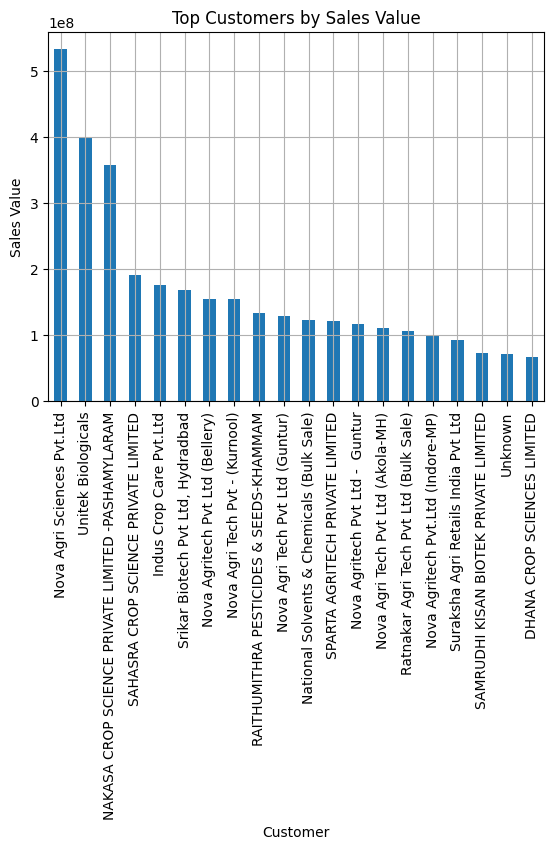

<Figure size 1200x600 with 0 Axes>

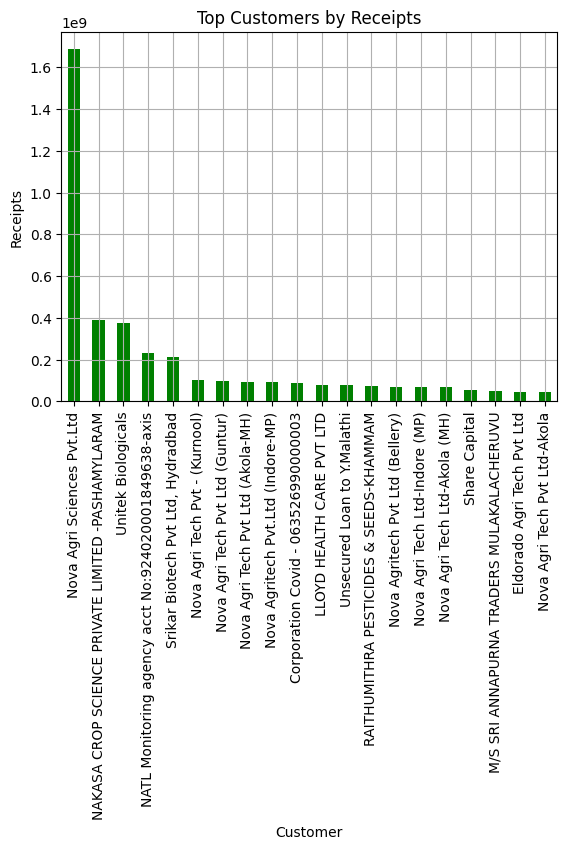

<Figure size 1200x600 with 0 Axes>

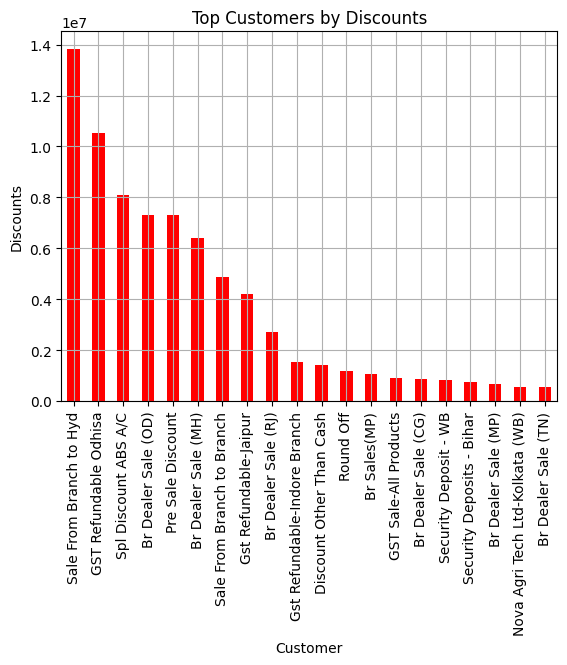

<Figure size 1200x600 with 0 Axes>

c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


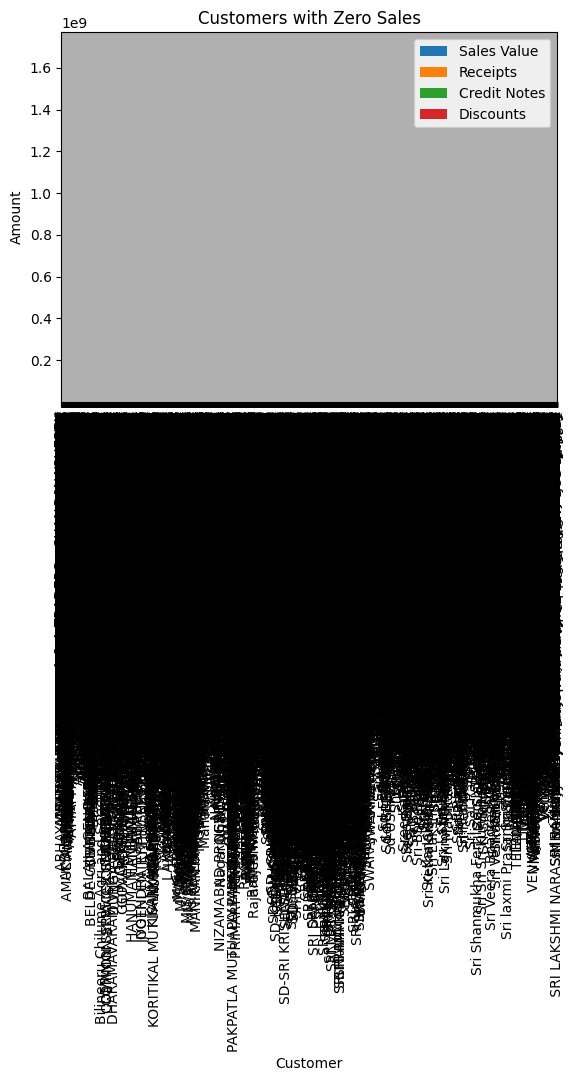

<Figure size 1200x600 with 0 Axes>

c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


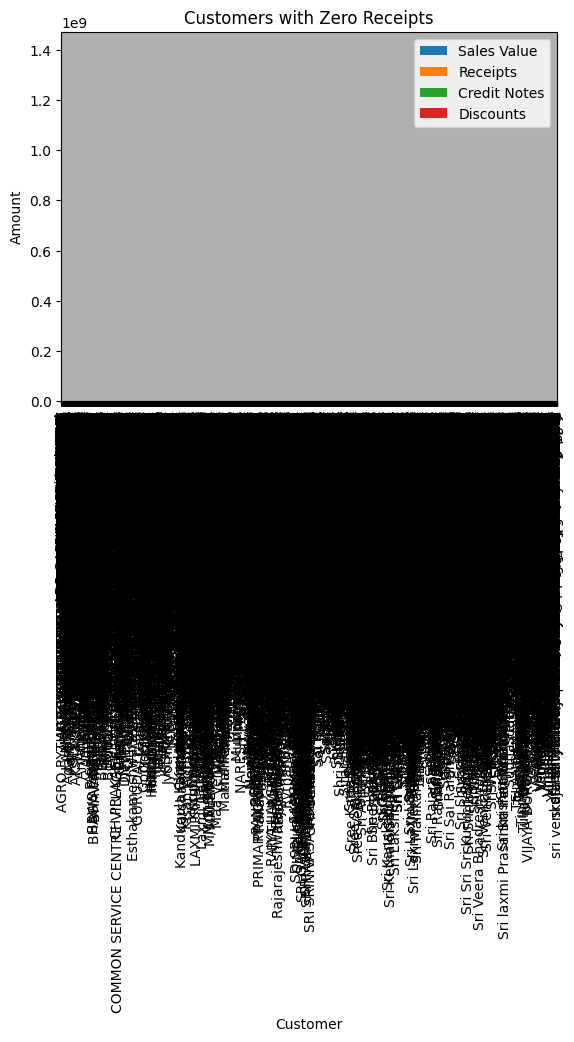

<Figure size 1200x600 with 0 Axes>

c:\Users\gzar9\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


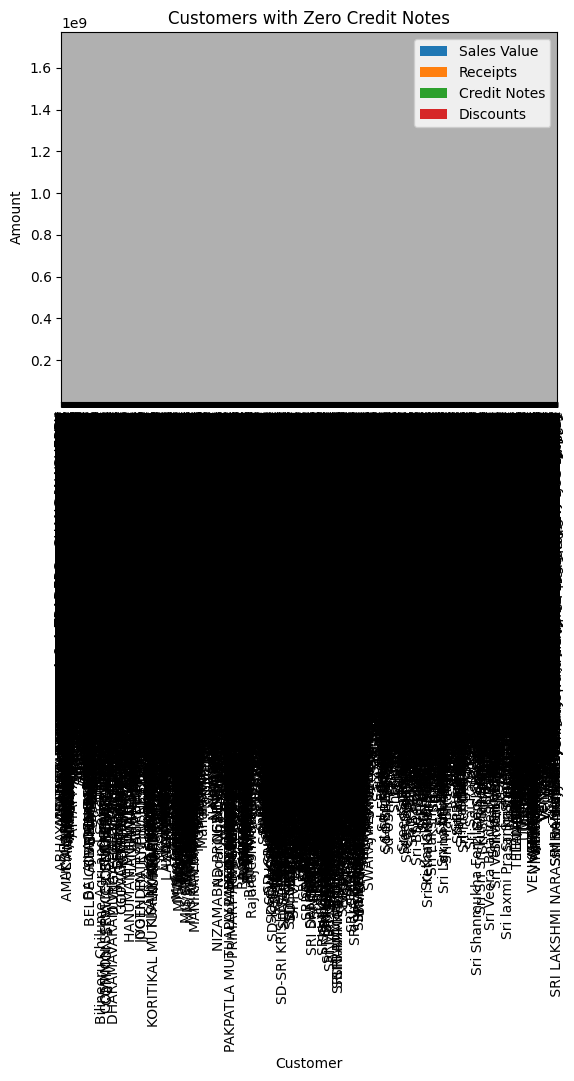

In [26]:
import matplotlib.pyplot as plt

# Plotting top customers by sales value
plt.figure(figsize=(12, 6))
top_customers_sales.sort_values(by='Sales Value', ascending=False).head(20).plot(kind='bar', y='Sales Value', legend=False)
plt.title('Top Customers by Sales Value')
plt.xlabel('Customer')
plt.ylabel('Sales Value')
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

# Plotting top customers by receipts
plt.figure(figsize=(12, 6))
top_customers_receipts.sort_values(by='Receipts', ascending=False).head(20).plot(kind='bar', y='Receipts', color='green', legend=False)
plt.title('Top Customers by Receipts')
plt.xlabel('Customer')
plt.ylabel('Receipts')
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

# Plotting top customers by discounts
plt.figure(figsize=(12, 6))
top_customers_discounts.sort_values(by='Discounts', ascending=False).head(20).plot(kind='bar', y='Discounts', color='red', legend=False)
plt.title('Top Customers by Discounts')
plt.xlabel('Customer')
plt.ylabel('Discounts')
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

# Plotting customers/products with zero sales, receipts, or credit notes
zero_sales_customers = zero_sales[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']]
zero_receipts_customers = zero_receipts[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']]
zero_credit_notes_customers = zero_credit_notes[['Sales Value', 'Receipts', 'Credit Notes', 'Discounts']]

# Visualize zero sales customers
plt.figure(figsize=(12, 6))
zero_sales_customers.plot(kind='bar', stacked=True)
plt.title('Customers with Zero Sales')
plt.xlabel('Customer')
plt.ylabel('Amount')
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

# Visualize zero receipts customers
plt.figure(figsize=(12, 6))
zero_receipts_customers.plot(kind='bar', stacked=True)
plt.title('Customers with Zero Receipts')
plt.xlabel('Customer')
plt.ylabel('Amount')
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

# Visualize zero credit notes customers
plt.figure(figsize=(12, 6))
zero_credit_notes_customers.plot(kind='bar', stacked=True)
plt.title('Customers with Zero Credit Notes')
plt.xlabel('Customer')
plt.ylabel('Amount')
plt.xticks(rotation=90)
plt.grid(True)
plt.show()
